In [146]:
# Importing Libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler , OneHotEncoder , OrdinalEncoder
from sklearn.impute import SimpleImputer , KNNImputer
from sklearn.base import BaseEstimator , TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    RandomizedSearchCV,
    GridSearchCV,
    KFold
)
from sklearn.linear_model import LogisticRegression , LinearRegression , SGDClassifier , SGDRegressor
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier , AdaBoostClassifier , BaggingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier , KNeighborsRegressor
from sklearn.svm import SVC , LinearSVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, make_scorer, confusion_matrix, mean_squared_error, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier

from scipy.stats import randint, uniform


1. Basic Data Cleaning and Creating Train/Test Split

In [147]:
raw_data = pd.read_csv('car_insurance_claim.csv')
raw_data.head()

,ID,KIDSDRIV,BIRTH,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,...,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CLM_AMT,CAR_AGE,CLAIM_FLAG,URBANICITY
0,63581743,0,16MAR39,60.0,0,11.0,"$67,349",No,$0,z_No,...,Minivan,yes,"$4,461",2,No,3,$0,18.0,0,Highly Urban/ Urban
1,132761049,0,21JAN56,43.0,0,11.0,"$91,449",No,"$257,252",z_No,...,Minivan,yes,$0,0,No,0,$0,1.0,0,Highly Urban/ Urban
2,921317019,0,18NOV51,48.0,0,11.0,"$52,881",No,$0,z_No,...,Van,yes,$0,0,No,2,$0,10.0,0,Highly Urban/ Urban
3,727598473,0,05MAR64,35.0,1,10.0,"$16,039",No,"$124,191",Yes,...,z_SUV,no,"$38,690",2,No,3,$0,10.0,0,Highly Urban/ Urban
4,450221861,0,05JUN48,51.0,0,14.0,NaN,No,"$306,251",Yes,...,Minivan,yes,$0,0,No,0,$0,6.0,0,Highly Urban/ Urban


# Basic Data Cleaning

In [148]:
data = raw_data.copy()
# Define updated column names
col_names = {
    'KIDSDRIV': 'num_young_drivers',
    'BIRTH': 'date_of_birth',
    'AGE': 'age',
    'HOMEKIDS': 'num_of_children',
    'YOJ': 'years_job_held_for',
    'INCOME': 'income',
    'PARENT1': 'single_parent',
    'HOME_VAL': 'value_of_home',
    'MSTATUS': 'married',
    'GENDER': 'gender',
    'EDUCATION': 'highest_education',
    'OCCUPATION': 'occupation',
    'TRAVTIME': 'commute_dist',
    'CAR_USE': 'type_of_use',
    'BLUEBOOK': 'vehicle_value',
    'TIF': 'policy_tenure',
    'CAR_TYPE': 'vehicle_type',
    'RED_CAR': 'red_vehicle',
    'OLDCLAIM': '5_year_total_claims_value',
    'CLM_FREQ': '5_year_num_of_claims',
    'REVOKED': 'licence_revoked',
    'MVR_PTS': 'license_points',
    'CLM_AMT': 'new_claim_value',
    'CAR_AGE': 'vehicle_age',
    'CLAIM_FLAG': 'is_claim',
    'URBANICITY': 'address_type'
}

# Rename the columns in the DataFrame
data.rename(columns=col_names, inplace=True)

C:\Users\viraa\AppData\Local\Temp\ipykernel_21388\3629394598.py:33: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=col_names, inplace=True)


In [149]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10302 entries, 0 to 10301
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         10302 non-null  int64  
 1   num_young_drivers          10302 non-null  int64  
 2   date_of_birth              10302 non-null  str    
 3   age                        10295 non-null  float64
 4   num_of_children            10302 non-null  int64  
 5   years_job_held_for         9754 non-null   float64
 6   income                     9732 non-null   str    
 7   single_parent              10302 non-null  str    
 8   value_of_home              9727 non-null   str    
 9   married                    10302 non-null  str    
 10  gender                     10302 non-null  str    
 11  highest_education          10302 non-null  str    
 12  occupation                 9637 non-null   str    
 13  commute_dist               10302 non-null  int64  
 14  t

In [150]:
data.duplicated().sum()

np.int64(1)

In [151]:
#Dropping Duplicates
data.drop_duplicates(inplace = True)

C:\Users\viraa\AppData\Local\Temp\ipykernel_21388\4091527294.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop_duplicates(inplace = True)


In [152]:
#Currency Conversion
cols = ['income', 'value_of_home', 'vehicle_value', '5_year_total_claims_value', 'new_claim_value']

def convert_currency(data, cols):
    for col in cols:
        data[col] = data[col].replace('[\$,]','', regex=True).astype('Int64')
    return data

data_df = convert_currency(data, cols)
data_df.info()


<class 'pandas.DataFrame'>
Index: 10301 entries, 0 to 10301
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         10301 non-null  int64  
 1   num_young_drivers          10301 non-null  int64  
 2   date_of_birth              10301 non-null  str    
 3   age                        10294 non-null  float64
 4   num_of_children            10301 non-null  int64  
 5   years_job_held_for         9753 non-null   float64
 6   income                     9731 non-null   Int64  
 7   single_parent              10301 non-null  str    
 8   value_of_home              9726 non-null   Int64  
 9   married                    10301 non-null  str    
 10  gender                     10301 non-null  str    
 11  highest_education          10301 non-null  str    
 12  occupation                 9636 non-null   str    
 13  commute_dist               10301 non-null  int64  
 14  type_o

In [153]:
z_prefix_cols = ['married', 'gender', 'highest_education', 'occupation', 'vehicle_type', 'address_type']

def z_prefix_remove(data,cols):
    for col in cols:
        data[col] = data[col].str.replace('z_', '', regex=True)
    return data

data_df = z_prefix_remove(data_df, z_prefix_cols)

In [154]:
data_df.drop(['date_of_birth','ID'], axis = 1 , inplace = True)

C:\Users\viraa\AppData\Local\Temp\ipykernel_21388\4113090158.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data_df.drop(['date_of_birth','ID'], axis = 1 , inplace = True)


In [155]:
claim_values = pd.to_numeric(
    data_df['new_claim_value'].astype('string').str.replace(r'[$,]', '', regex=True),
    errors='coerce'
)

mask = (claim_values > 0) & (data_df['is_claim'] == 0)
data_df[mask]

,num_young_drivers,age,num_of_children,years_job_held_for,income,single_parent,value_of_home,married,gender,highest_education,...,vehicle_type,red_vehicle,5_year_total_claims_value,5_year_num_of_claims,licence_revoked,license_points,new_claim_value,vehicle_age,is_claim,address_type


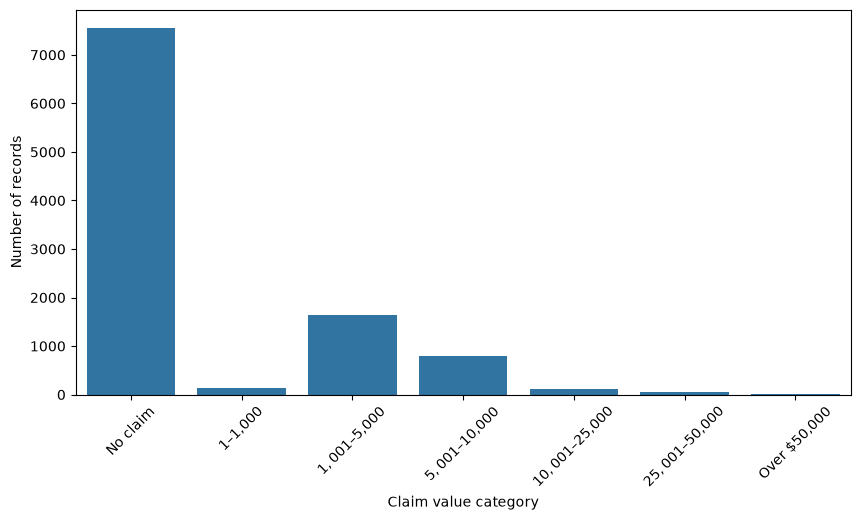

In [156]:
bins = [-np.inf, 0, 1000, 5000, 10000, 25000, 50000, np.inf]
labels = [
    'No claim',
    '$1–$1,000',
    '$1,001–$5,000',
    '$5,001–$10,000',
    '$10,001–$25,000',
    '$25,001–$50,000',
    'Over $50,000'
]

data_df['claim_value_cat'] = pd.cut(
    claim_values.astype(float),
    bins=bins,
    labels=labels,
    include_lowest=True
)

plt.figure(figsize=(10, 5))
sns.countplot(data=data_df, x='claim_value_cat')
plt.xlabel('Claim value category')
plt.ylabel('Number of records')
plt.xticks(rotation=45)
plt.show()

In [157]:
# Train-Test Split

X = data_df.copy()
y = data_df['is_claim']

# Drop target and target-related features
X = X.drop(
    ['is_claim', 'new_claim_value', 'claim_value_cat'],
    axis=1
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [158]:
train_ratio = round((y_train.sum()/len(y_train))*100,2)
test_ratio = round((y_test.sum()/len(y_test)*100),2)

print(f'Train positive class ratio: {train_ratio}%')
print(f'Test positive class ratio: {test_ratio}%')

Train positive class ratio: 26.66%
Test positive class ratio: 26.64%


# Data Preperation For EDA

In [159]:
eda_test_data = X_train.copy()
eda_test_data['is_claim'] = y_train

In [160]:
binary_cols = ['single_parent', 'married', 'gender', 'red_vehicle', 'licence_revoked']

# Define map values
mapping = {'Yes': 1,
           'No': 0,
           'yes': 1,
           'no': 0,
           'M': 1,
           'F': 0,
           }

# Define function to binarise features
def binary_mapping(data, cols, map):
    for col in cols:
        data[col] = data[col].map(map)
    return data
eda_test_data = binary_mapping(eda_test_data, binary_cols, mapping)
eda_test_data.head()

,num_young_drivers,age,num_of_children,years_job_held_for,income,single_parent,value_of_home,married,gender,highest_education,...,policy_tenure,vehicle_type,red_vehicle,5_year_total_claims_value,5_year_num_of_claims,licence_revoked,license_points,vehicle_age,address_type,is_claim
9136,0,55.0,0,13.0,32880,0,197778,1,1,<High School,...,11,Pickup,1,0,0,0,3,1.0,Highly Urban/ Urban,1
2145,2,40.0,3,14.0,<NA>,0,168365,1,0,Bachelors,...,6,Minivan,0,0,0,0,0,15.0,Highly Rural/ Rural,0
5839,0,39.0,1,17.0,14054,0,98184,1,0,<High School,...,6,Minivan,0,0,0,0,4,1.0,Highly Rural/ Rural,0
532,2,41.0,3,10.0,24862,1,0,0,0,Bachelors,...,1,Sports Car,0,1055,4,0,2,10.0,Highly Rural/ Rural,1
2948,0,51.0,0,12.0,101859,0,272958,1,0,PhD,...,4,Sports Car,0,0,0,1,0,17.0,Highly Rural/ Rural,1


In [161]:
eda_test_data.corr(numeric_only=True).sort_values(by='is_claim',ascending=False)

,num_young_drivers,age,num_of_children,years_job_held_for,income,single_parent,value_of_home,married,gender,commute_dist,vehicle_value,policy_tenure,red_vehicle,5_year_total_claims_value,5_year_num_of_claims,licence_revoked,license_points,vehicle_age,is_claim
is_claim,0.115855,-0.106530,0.123245,-0.064168,-0.142316,0.160859,-0.186161,-0.132074,-0.025425,0.047426,-0.097635,-0.077431,-0.006339,0.146048,0.224980,0.152988,0.216288,-0.100919,1.000000
5_year_num_of_claims,0.041319,-0.037868,0.039418,-0.025394,-0.053356,0.066286,-0.099306,-0.074476,0.017719,0.010874,-0.046459,-0.014313,0.029491,0.484525,1.000000,0.052722,0.398162,-0.017116,0.224980
license_points,0.048764,-0.075681,0.063798,-0.047593,-0.065611,0.063944,-0.091844,-0.049808,-0.011904,0.013892,-0.044538,-0.028320,0.004245,0.254130,0.398162,0.050848,1.000000,-0.030252,0.216288
single_parent,0.213431,-0.306697,0.450285,-0.032559,-0.066617,1.000000,-0.245446,-0.473875,-0.066122,-0.013120,-0.042567,0.010417,-0.040424,0.039960,0.066286,0.057171,0.063944,-0.065870,0.160859
licence_revoked,0.034733,-0.043521,0.044013,-0.010382,-0.023237,0.057171,-0.033005,-0.032491,-0.016116,-0.004263,-0.036986,-0.031551,-0.008491,0.422738,0.052722,1.000000,0.050848,-0.011955,0.152988
5_year_total_claims_value,0.029000,-0.034716,0.029349,-0.009996,-0.040639,0.039960,-0.057903,-0.047386,-0.005718,-0.010962,-0.033876,-0.014992,0.005467,1.000000,0.484525,0.422738,0.254130,-0.014537,0.146048
num_of_children,0.457590,-0.454852,1.000000,0.076092,-0.156739,0.450285,-0.099715,0.045088,-0.110115,0.002389,-0.112679,0.001985,-0.065608,0.029349,0.039418,0.044013,0.063798,-0.154819,0.123245
num_young_drivers,1.000000,-0.088244,0.457590,0.035768,-0.038518,0.213431,-0.013560,0.032553,-0.028035,0.019410,-0.033556,-0.012364,-0.027397,0.029000,0.041319,0.034733,0.048764,-0.057782,0.115855
commute_dist,0.019410,-0.002248,0.002389,-0.012852,-0.045443,-0.013120,-0.031693,0.001604,-0.009485,1.000000,-0.023853,-0.008200,0.003808,-0.010962,0.010874,-0.004263,0.013892,-0.030758,0.047426
red_vehicle,-0.027397,0.036378,-0.065608,0.051971,0.065362,-0.040424,0.023153,-0.024545,0.660491,0.003808,0.025301,-0.008256,1.000000,0.005467,0.029491,-0.008491,0.004245,0.011942,-0.006339


<Axes: >

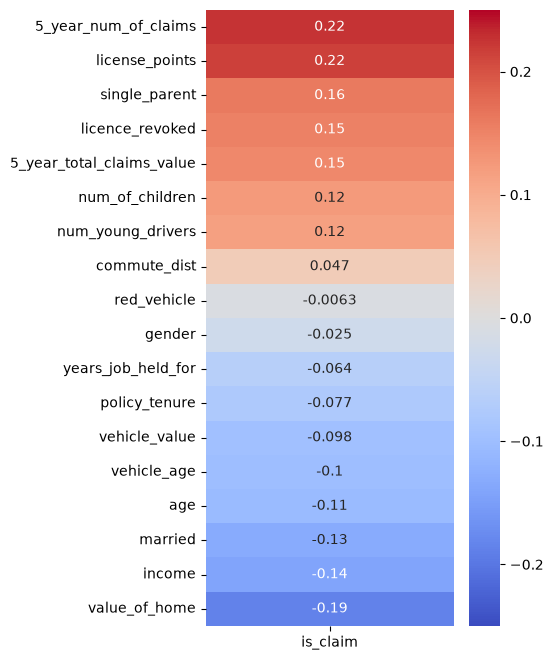

In [162]:
fig, ax = plt.subplots(figsize=(4, 8))

corr_matrix = eda_test_data.corr(numeric_only=True).sort_values(by='is_claim',ascending=False)
corr_matrix_no_claim = corr_matrix.drop('is_claim')

sns.heatmap(corr_matrix_no_claim[['is_claim']],cmap='coolwarm', annot=True, vmax=0.25, vmin=-0.25)

In [163]:
X_train_raw = X_train.copy()
cols_to_drop = [
    'red_vehicle',
]
X_train_raw.drop(cols_to_drop, axis=1, inplace=True)


C:\Users\viraa\AppData\Local\Temp\ipykernel_21388\210360875.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_train_raw.drop(cols_to_drop, axis=1, inplace=True)


In [164]:
X_train_raw.isnull().sum().sum()

np.int64(2367)

# Create the imputer

In [165]:
knn = KNNImputer(n_neighbors=2)
numerical_cols = X_train_raw.select_dtypes(include=['number'])
numerical_cols_list = numerical_cols.columns.tolist()

categorical_cols = X_train_raw.select_dtypes(include=['object'])
categorical_cols_list = categorical_cols.columns.tolist()

C:\Users\viraa\AppData\Local\Temp\ipykernel_21388\2066458629.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train_raw.select_dtypes(include=['object'])


In [166]:
# Define Function to impute missing values for numerical columns

def impute_missing_values(data,cols,imputer):
    data = data[cols]
    data_imputed = pd.DataFrame(imputer.fit_transform(data))
    data_imputed.columns = data.columns
    return data_imputed
num_test_data_imputed = impute_missing_values(X_train_raw, numerical_cols_list, knn)

In [167]:
# Get numerical cols as a df
num_cols_df = X_train_raw[numerical_cols_list].reset_index(drop=True)
# Select rows with missing values and show head
missing_data_df = num_cols_df[num_cols_df.isna().any(axis=1)]
missing_data_df.head()

,num_young_drivers,age,num_of_children,years_job_held_for,income,value_of_home,commute_dist,vehicle_value,policy_tenure,5_year_total_claims_value,5_year_num_of_claims,license_points,vehicle_age
1,2,40.0,3,14.0,<NA>,168365,33,24160,6,0,0,0,15.0
8,0,53.0,0,14.0,103536,<NA>,33,17150,15,0,0,0,12.0
9,2,39.0,2,NaN,64990,197575,5,17510,10,0,0,0,7.0
16,0,38.0,0,NaN,<NA>,305294,48,16810,1,0,0,1,14.0
18,0,44.0,0,14.0,98369,<NA>,15,34270,10,0,0,2,1.0


In [168]:
# Show same records after imputation
samples = missing_data_df.index.to_list()
num_test_data_imputed.loc[samples].head()

KeyError: '[26, 78, 137, 166, 264, 265, 266, 295, 340, 412, 428, 466, 478, 547, 556, 570, 607, 632, 645, 674, 685, 699, 708, 713, 728, 746, 779, 833, 841, 873, 908, 914, 926, 972, 978, 1014, 1046, 1054, 1055, 1077, 1160, 1165, 1181, 1221, 1229, 1253, 1298, 1320, 1326, 1333, 1346, 1399, 1430, 1449, 1451, 1452, 1468, 1532, 1553, 1568, 1578, 1582, 1595, 1652, 1751, 1773, 1791, 1795, 1815, 1864, 1888, 1915, 1928, 1978, 1995, 2100, 2104, 2119, 2130, 2161, 2167, 2181, 2202, 2204, 2223, 2246, 2256, 2284, 2298, 2354, 2404, 2452, 2472, 2533, 2544, 2557, 2599, 2612, 2634, 2699, 2722, 2736, 2765, 2793, 2804, 2805, 2814, 2825, 2831, 3015, 3018, 3021, 3071, 3099, 3131, 3146, 3183, 3187, 3198, 3207, 3216, 3223, 3244, 3254, 3272, 3276, 3304, 3336, 3353, 3372, 3410, 3451, 3465, 3516, 3522, 3562, 3564, 3596, 3613, 3653, 3668, 3684, 3700, 3704, 3714, 3733, 3736, 3741, 3761, 3768, 3778, 3792, 3816, 3822, 3825, 3841, 3873, 3902, 3911, 3936, 3974, 3994, 4006, 4059, 4062, 4112, 4117, 4124, 4156, 4186, 4194,

In [ ]:
# Define Function to impute missing values for categorical columns
simple_imputer = SimpleImputer(strategy='most_frequent')
def impute_categorical_missing_values(data, cols, imputer):
    data = data[cols]
    data_imputed = pd.DataFrame(imputer.fit_transform(data))
    data_imputed.columns = data.columns
    return data_imputed
cat_test_data_imputed = impute_categorical_missing_values(X_train_raw, categorical_cols_list, simple_imputer)

In [ ]:
# Get numerical cols as a df
cat_cols_df = X_train_raw[categorical_cols_list].reset_index(drop=True)
# Select rows with missing values and show head
missing_cat_data_df = cat_cols_df[num_cols_df.isna().any(axis=1)]
missing_cat_data_df.head()

,single_parent,married,gender,highest_education,occupation,type_of_use,vehicle_type,licence_revoked,address_type
1,No,Yes,F,Bachelors,Professional,Private,Minivan,No,Highly Rural/ Rural
8,No,No,M,Bachelors,Manager,Private,Van,No,Highly Urban/ Urban
9,No,Yes,F,High School,Professional,Commercial,Pickup,No,Highly Urban/ Urban
16,No,Yes,F,PhD,Lawyer,Private,Minivan,No,Highly Urban/ Urban
18,No,No,F,High School,Manager,Commercial,Pickup,No,Highly Urban/ Urban


In [ ]:
# Show same records after imputation
samples = missing_cat_data_df.index.to_list()
cat_test_data_imputed.loc[samples].head()

,single_parent,married,gender,highest_education,occupation,type_of_use,vehicle_type,licence_revoked,address_type
1,No,Yes,F,Bachelors,Professional,Private,Minivan,No,Highly Rural/ Rural
8,No,No,M,Bachelors,Manager,Private,Van,No,Highly Urban/ Urban
9,No,Yes,F,High School,Professional,Commercial,Pickup,No,Highly Urban/ Urban
16,No,Yes,F,PhD,Lawyer,Private,Minivan,No,Highly Urban/ Urban
18,No,No,F,High School,Manager,Commercial,Pickup,No,Highly Urban/ Urban


In [ ]:
# Combine the imputed numerical and categorical dataframes
imputed_data = pd.concat([num_test_data_imputed, cat_test_data_imputed], axis=1)
imputed_data.head()

,num_young_drivers,age,num_of_children,years_job_held_for,income,value_of_home,commute_dist,vehicle_value,policy_tenure,5_year_total_claims_value,...,vehicle_age,single_parent,married,gender,highest_education,occupation,type_of_use,vehicle_type,licence_revoked,address_type
0,0.0,55.0,0.0,13.0,32880.0,197778.0,27.0,4790.0,11.0,0.0,...,1.0,No,Yes,M,<High School,Blue Collar,Commercial,Pickup,No,Highly Urban/ Urban
1,2.0,40.0,3.0,14.0,80461.5,168365.0,33.0,24160.0,6.0,0.0,...,15.0,No,Yes,F,Bachelors,Professional,Private,Minivan,No,Highly Rural/ Rural
2,0.0,39.0,1.0,17.0,14054.0,98184.0,35.0,13690.0,6.0,0.0,...,1.0,No,Yes,F,<High School,Clerical,Private,Minivan,No,Highly Rural/ Rural
3,2.0,41.0,3.0,10.0,24862.0,0.0,26.0,7790.0,1.0,1055.0,...,10.0,Yes,No,F,Bachelors,Student,Private,Sports Car,No,Highly Rural/ Rural
4,0.0,51.0,0.0,12.0,101859.0,272958.0,48.0,13390.0,4.0,0.0,...,17.0,No,Yes,F,PhD,Professional,Private,Sports Car,Yes,Highly Rural/ Rural


In [ ]:
imputed_data.isnull().sum()

num_young_drivers            0
age                          0
num_of_children              0
years_job_held_for           0
income                       0
value_of_home                0
commute_dist                 0
vehicle_value                0
policy_tenure                0
5_year_total_claims_value    0
5_year_num_of_claims         0
license_points               0
vehicle_age                  0
single_parent                0
married                      0
gender                       0
highest_education            0
occupation                   0
type_of_use                  0
vehicle_type                 0
licence_revoked              0
address_type                 0
dtype: int64

In [ ]:
# Define ordinal features
cat_cols_ord = ['highest_education']
# Define binary features
cat_cols_bin = ['single_parent', 'married', 'gender', 'type_of_use', 'licence_revoked', 'address_type']
# Define one-hot features
cat_cols_one_hot = ['occupation', 'vehicle_type']

In [ ]:
education_rank = [['<High School', 'High School', 'Bachelors', 'Masters', 'PhD']]
ordinal_encoder = OrdinalEncoder(categories=education_rank)
bin_encoder = OrdinalEncoder()
one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

In [ ]:
# Encoding features

ordinal_encoded_data = ordinal_encoder.fit_transform(cat_test_data_imputed[cat_cols_ord])
binary_encoded_data = bin_encoder.fit_transform(cat_test_data_imputed[cat_cols_bin])
one_hot_encoded = one_hot_encoder.fit_transform(cat_test_data_imputed[cat_cols_one_hot])

In [ ]:
# Create dfs for each array
ord_encoded_df = pd.DataFrame(ordinal_encoded_data)
ord_encoded_df.columns = cat_cols_ord

bin_encoded_df = pd.DataFrame(binary_encoded_data)
bin_encoded_df.columns = cat_cols_bin

one_hot_encoded_df = pd.DataFrame(one_hot_encoded)
one_hot_encoded_df.columns = one_hot_encoder.get_feature_names_out()

# Join encoded dfs to a single df and show head
all_cat_encoded_df = pd.concat([ord_encoded_df, bin_encoded_df, one_hot_encoded_df], axis=1)
all_cat_encoded_df.head()

,highest_education,single_parent,married,gender,type_of_use,licence_revoked,address_type,occupation_Blue Collar,occupation_Clerical,occupation_Doctor,...,occupation_Lawyer,occupation_Manager,occupation_Professional,occupation_Student,vehicle_type_Minivan,vehicle_type_Panel Truck,vehicle_type_Pickup,vehicle_type_SUV,vehicle_type_Sports Car,vehicle_type_Van
0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,2.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,2.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,4.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
# Join numerical and categorical data
X_train_cleaned = pd.concat([imputed_data[numerical_cols_list], all_cat_encoded_df], axis=1)
X_train_cleaned.head()

,num_young_drivers,age,num_of_children,years_job_held_for,income,value_of_home,commute_dist,vehicle_value,policy_tenure,5_year_total_claims_value,...,occupation_Lawyer,occupation_Manager,occupation_Professional,occupation_Student,vehicle_type_Minivan,vehicle_type_Panel Truck,vehicle_type_Pickup,vehicle_type_SUV,vehicle_type_Sports Car,vehicle_type_Van
0,0.0,55.0,0.0,13.0,32880.0,197778.0,27.0,4790.0,11.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,2.0,40.0,3.0,14.0,80461.5,168365.0,33.0,24160.0,6.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.0,39.0,1.0,17.0,14054.0,98184.0,35.0,13690.0,6.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,2.0,41.0,3.0,10.0,24862.0,0.0,26.0,7790.0,1.0,1055.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,51.0,0.0,12.0,101859.0,272958.0,48.0,13390.0,4.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
# Function to calculate VIF
def calculate_vif(dataframe):
    # Add a constant to the DataFrame (intercept term)
    df_with_constant = add_constant(dataframe)

    # Calculate VIF for each feature
    vif_data = pd.DataFrame()
    vif_data["Feature"] = df_with_constant.columns
    vif_data["VIF"] = [variance_inflation_factor(df_with_constant.values, i)
                       for i in range(df_with_constant.shape[1])]

    return vif_data

# Calculate VIF for encoded data
vif_df = calculate_vif(X_train_cleaned)
vif_df

C:\Users\viraa\AppData\Local\Temp\ipykernel_21388\2164780470.py:9: UserWarning: The design matrix is poorly conditioned (condition number=2.61e+15). VIF calculations may be numerically unstable.
  vif_data["VIF"] = [variance_inflation_factor(df_with_constant.values, i)
c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model para

c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model param

,Feature,VIF
0,const,1.000000e+00
1,num_young_drivers,1.308677e+00
2,age,1.464396e+00
3,num_of_children,2.078666e+00
4,years_job_held_for,1.453458e+00
5,income,2.711225e+00
6,value_of_home,2.131860e+00
7,commute_dist,1.036301e+00
8,vehicle_value,2.073371e+00
9,policy_tenure,1.006204e+00


In [ ]:
X_train_cleaned.drop(['occupation_Blue Collar' ,'vehicle_type_Minivan'], axis=1, inplace=True)

C:\Users\viraa\AppData\Local\Temp\ipykernel_21388\259214127.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_train_cleaned.drop(['occupation_Blue Collar' ,'vehicle_type_Minivan'], axis=1, inplace=True)


In [ ]:
# Calculate VIF for encoded data
vif_df = calculate_vif(X_train_cleaned)
vif_df

,Feature,VIF
0,const,1.000000
1,num_young_drivers,1.308677
2,age,1.464396
3,num_of_children,2.078666
4,years_job_held_for,1.453458
5,income,2.711225
6,value_of_home,2.131860
7,commute_dist,1.036301
8,vehicle_value,2.073371
9,policy_tenure,1.006204


# Model Selection

In [ ]:
classifier = [
    ('Logistic Regression', LogisticRegression(solver='liblinear', max_iter=2000)),
    ('KNN', KNeighborsClassifier()),
    ('Decision Tree', DecisionTreeClassifier()),
    ('Random Forest', RandomForestClassifier(random_state=42)),
    ('XGBoost', XGBClassifier(random_state=42)),
    ('Gradient Boost', GradientBoostingClassifier(random_state=42)),
]

In [ ]:
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
results ={}

for name,model in classifier:
    cv_results = cross_val_score(model,X_train_cleaned,y_train,cv=kfold)
    results[name] = cv_results

cv_score_df =pd.DataFrame(results)

Text(0.5, 1.0, 'Cross-Validation Scores for Different Classifiers')

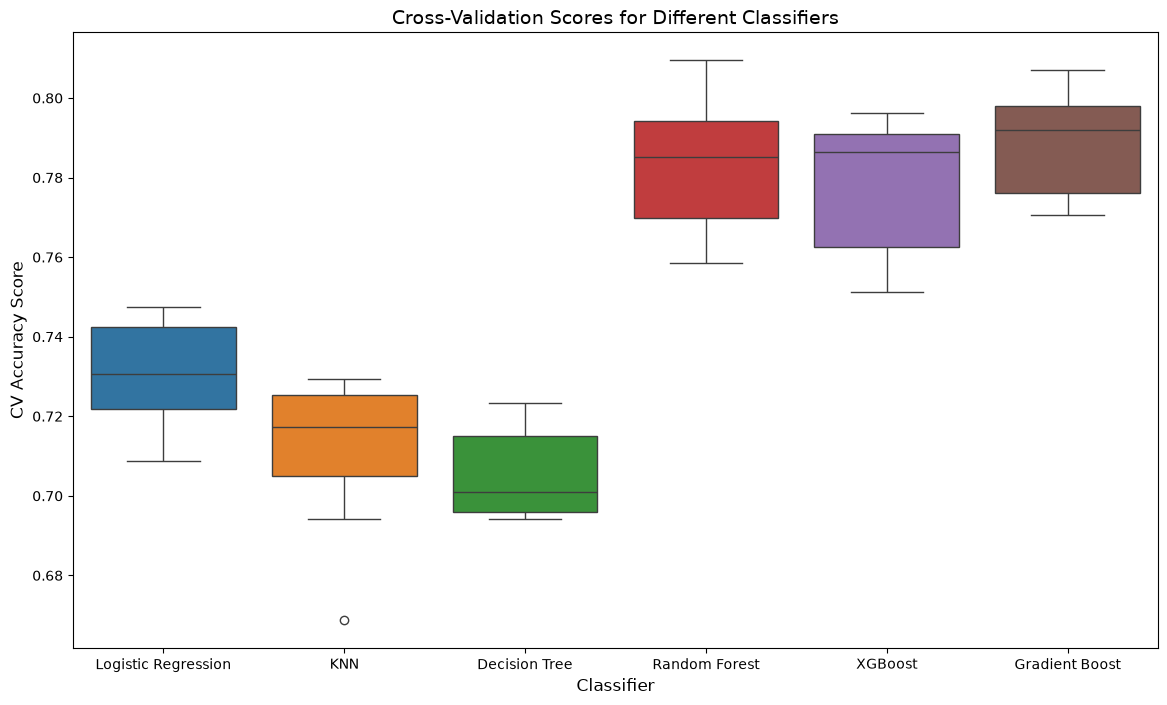

In [ ]:
# Plot scores
fig, ax = plt.subplots(figsize=(14, 8))
sns.boxplot(cv_score_df)

# Add axis labels
ax.set_xlabel('Classifier', fontsize=12)
ax.set_ylabel('CV Accuracy Score', fontsize=12)
ax.set_title('Cross-Validation Scores for Different Classifiers', fontsize=14)

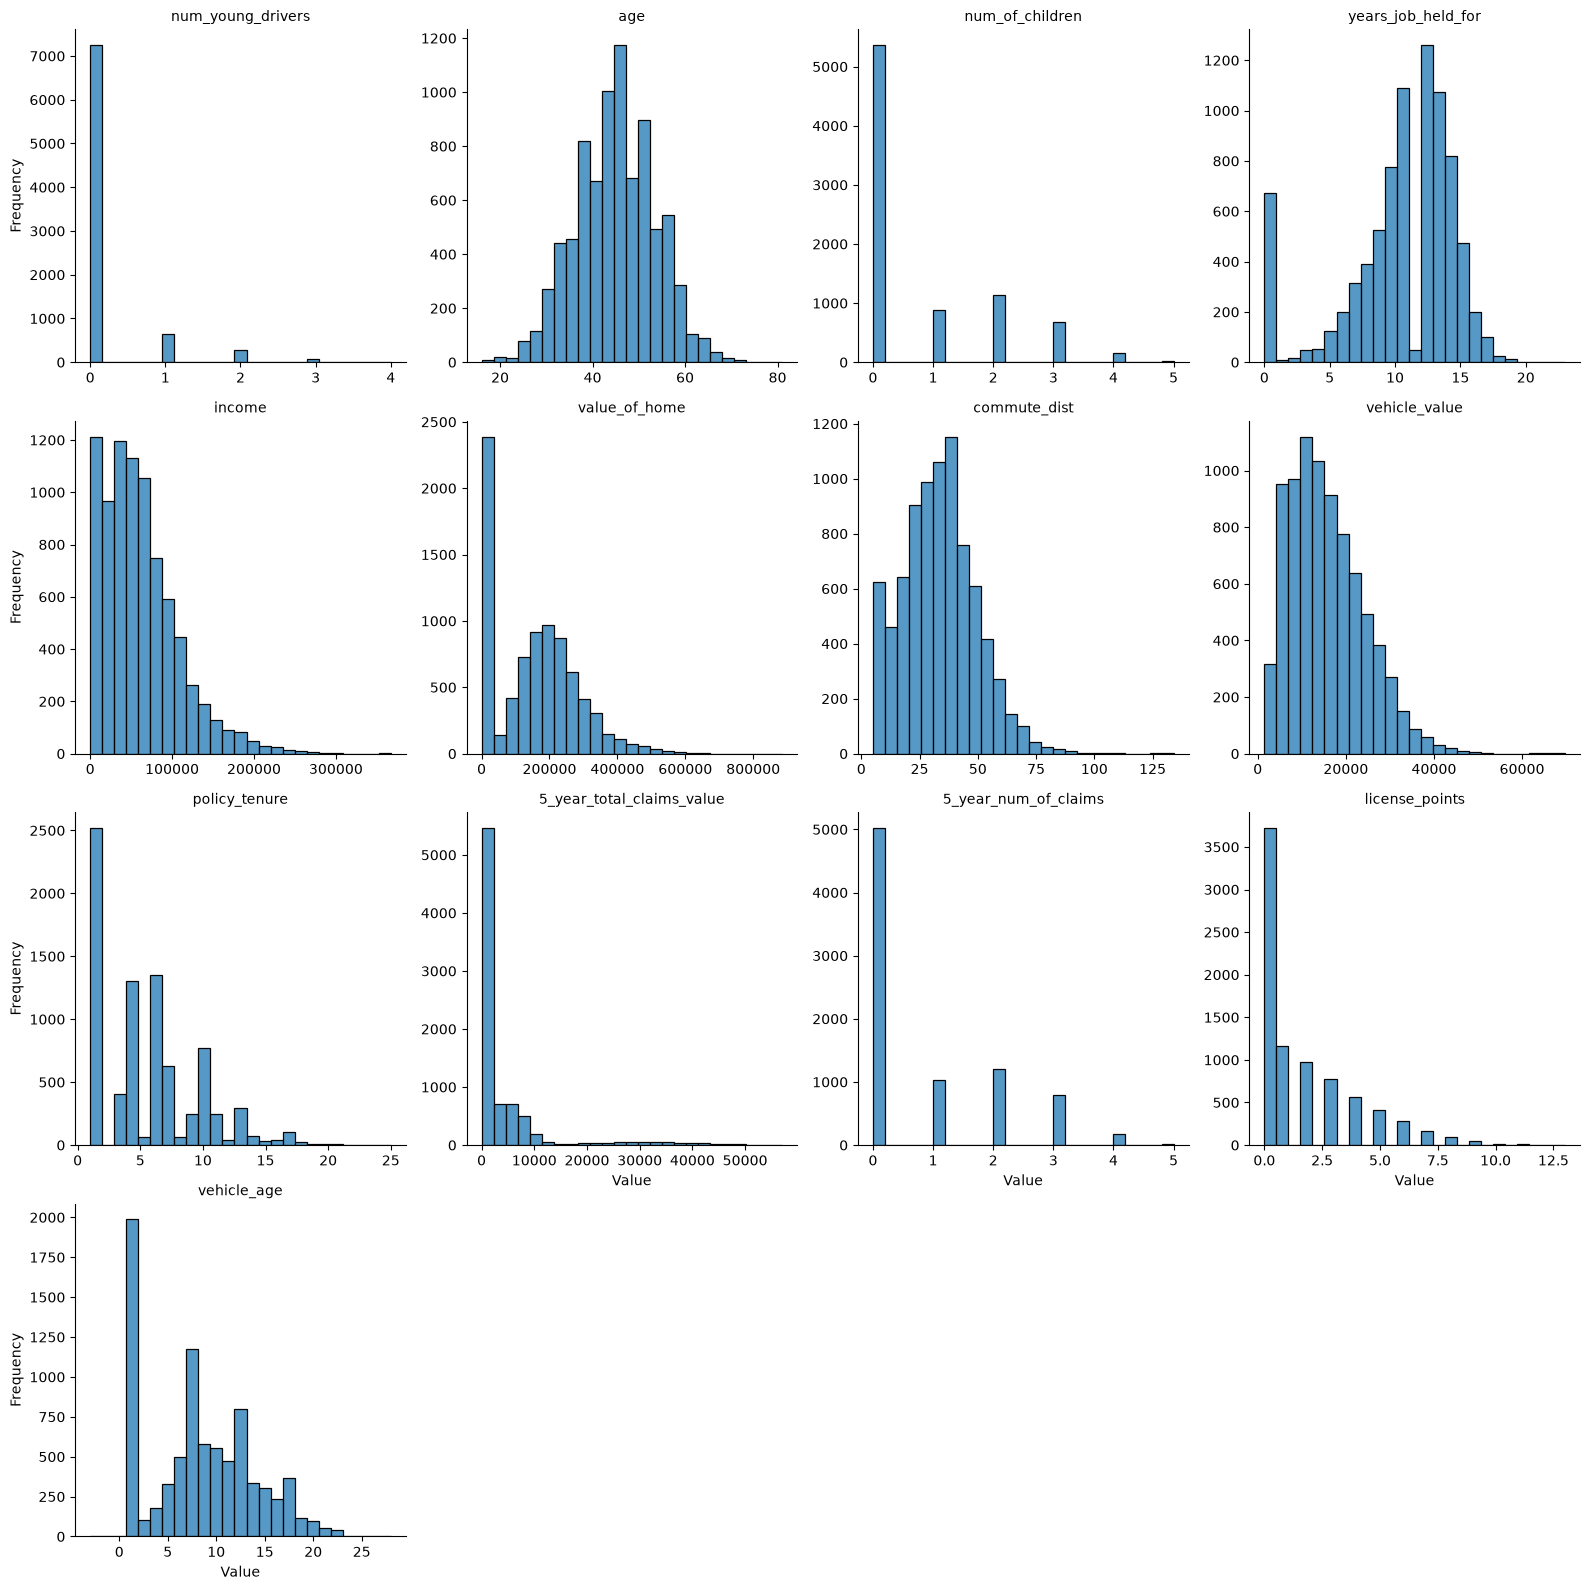

In [ ]:
# Melt the DataFrame to long format
melted_X_train = X_train_cleaned[numerical_cols_list].melt(var_name='Column', value_name='Value')

# Create a FacetGrid
g = sns.FacetGrid(melted_X_train, col='Column', col_wrap=4, sharex=False, sharey=False, height=4)

# Map the sns.histplot to each facet
g.map(sns.histplot, 'Value', bins=25)

# Add titles and labels
g.set_axis_labels('Value', 'Frequency')
g.set_titles(col_template='{col_name}')

plt.tight_layout()
plt.show()

In [ ]:
# Define features we right skew
skewed_features = ['income', 'value_of_home', 'commute_dist', 'vehicle_value', 'policy_tenure', 'license_points']

# Define function to apply log transform
def log_of_feature(data_df, skewed_features):
    data = data_df.copy()
    for feature in skewed_features:
        data[feature] = np.sqrt(data[feature])
    return data

# Apply the function to X_train
X_train_cleaned_log = log_of_feature(X_train_cleaned, skewed_features)

In [ ]:
# Define features we right skew
skewed_features = ['income', 'value_of_home', 'commute_dist', 'vehicle_value', 'policy_tenure', 'license_points']

# Define function to apply log transform
def log_of_feature(data_df, skewed_features):
    data = data_df.copy()
    for feature in skewed_features:
        data[feature] = np.sqrt(data[feature])
    return data

# Apply the function to X_train
X_train_cleaned_log = log_of_feature(X_train_cleaned, skewed_features)

In [ ]:
xgb_boost_clf = XGBClassifier(random_state=42)

cv_scores = cross_val_score(xgb_boost_clf, X_train_cleaned, y_train, cv=kfold)
cv_scores_log = cross_val_score(xgb_boost_clf, X_train_cleaned_log, y_train, cv=kfold)

print(f'CV score without log transform: {cv_scores.mean()}')
print(f'CV score with log transform: {cv_scores_log.mean()}')

CV score without log transform: 0.7781553398058252
CV score with log transform: 0.7781553398058252


In [ ]:
# Define function to scale numeric features
def scale_features(data_df, numeric_features):
    data = data_df.copy()
    # Initialise scaler
    scaler = StandardScaler()
    # Fit scaler to training data
    scaler.fit(data[numeric_features])
    # Transform numeric features
    data[numeric_features] = scaler.transform(data[numeric_features])
    return data

# Apply the function to X_train
X_train_cleaned_scaled = scale_features(X_train_cleaned_log, numerical_cols_list)

In [ ]:
xgb_boost_clf = XGBClassifier(random_state=42)

cv_scores = cross_val_score(xgb_boost_clf, X_train_cleaned, y_train, cv=kfold)
cv_scores_scaled = cross_val_score(xgb_boost_clf, X_train_cleaned_scaled, y_train, cv=kfold)

print(f'CV score without log transform: {cv_scores.mean()}')
print(f'CV score with log transform: {cv_scores_scaled.mean()}')

CV score without log transform: 0.7781553398058252
CV score with log transform: 0.7781553398058252


# Custome Transformer

In [ ]:
X_train_cleaned = X_train_cleaned_scaled.copy()

In [ ]:
class CustomDropper(BaseEstimator,TransformerMixin):
    def __init__(self,columns_to_drop):
        self.columns_to_drop = columns_to_drop
    def fit(self,X,y=None):
        return self
    def transform(self,X,y=None):
        return X.drop(columns=self.columns_to_drop)
    def get_feature_names_out(self,input_feaatures=None):
        return None

In [ ]:
class SqrtTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, columns_to_transform):
        self.columns_to_transform = columns_to_transform
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        X[self.columns_to_transform] = np.sqrt(X[self.columns_to_transform])
        return X

    def get_feature_names_out(self, input_features=None):
        return input_features

# Pipeline

In [ ]:
from sklearn import set_config
set_config(transform_output='pandas')

In [ ]:
cols_to_drop_pipeline = Pipeline([
    ('columns_drop', CustomDropper(cols_to_drop))
])

skewed_features = [
    'income', 'value_of_home', 'commute_dist',
    'vehicle_value', 'policy_tenure', 'license_points'
]

num_pipeline = Pipeline([
    ('knn_imputer', KNNImputer(n_neighbors=2)),
    ('sqrt', SqrtTransformer(skewed_features)),
    ('scaler', StandardScaler())
])

education_rank = [['<High School', 'High School', 'Bachelors', 'Masters', 'PhD']]

cat_ord_pipeline = Pipeline([
    ('simple_imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal_encoder', OrdinalEncoder(categories=education_rank))
])

cat_bin_pipeline = Pipeline([
    ('simple_imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal_encoder', OrdinalEncoder())
])

cat_one_hot_pipeline = Pipeline([
    ('simple_imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot_encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False,
        drop='first'
    ))
])

preprocess_pipeline = ColumnTransformer([
    ('drop_features', cols_to_drop_pipeline, cols_to_drop),
    ('num', num_pipeline, numerical_cols_list),
    ('cat_ord', cat_ord_pipeline, cat_cols_ord),
    ('cat_bin', cat_bin_pipeline, cat_cols_bin),
    ('cat_one_hot', cat_one_hot_pipeline, cat_cols_one_hot)
])

In [ ]:
X_train_prepared = preprocess_pipeline.fit_transform(X_train)

In [ ]:
# Create df from processed data
X_train_prepared_df = pd.DataFrame(
    X_train_prepared,
    columns=preprocess_pipeline.get_feature_names_out(),
)

# Get names of new one-hot columns
one_hot_col_names = list(preprocess_pipeline.transformers_[4][1][1].get_feature_names_out(cat_cols_one_hot))

# Create list of all columns names
new_col_names = (
    numerical_cols_list
    + cat_cols_ord
    + cat_cols_bin
    + one_hot_col_names
)

# Rename df columns
X_train_prepared_df.columns = new_col_names

# Reset index
X_train_prepared_df.reset_index(drop=True, inplace=True)

# Inspect df
X_train_prepared_df.head()

C:\Users\viraa\AppData\Local\Temp\ipykernel_21388\147641200.py:22: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_train_prepared_df.reset_index(drop=True, inplace=True)


,num_young_drivers,age,num_of_children,years_job_held_for,income,value_of_home,commute_dist,vehicle_value,policy_tenure,5_year_total_claims_value,...,occupation_Home Maker,occupation_Lawyer,occupation_Manager,occupation_Professional,occupation_Student,vehicle_type_Panel Truck,vehicle_type_Pickup,vehicle_type_SUV,vehicle_type_Sports Car,vehicle_type_Van
0,-0.335183,1.180741,-0.643650,0.625169,-0.395089,0.547996,-0.278120,-1.498152,1.300481,-0.461324,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,3.618870,-0.564645,2.035876,0.868405,0.569980,0.393464,0.099543,1.022621,0.349750,-0.461324,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.335183,-0.681004,0.249525,1.598115,-0.987159,-0.042199,0.217658,-0.100890,0.349750,-0.461324,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3.618870,-0.448286,2.035876,-0.104542,-0.618148,-1.449831,-0.345010,-0.941195,-1.239478,-0.340153,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,-0.335183,0.715305,-0.643650,0.381932,0.904746,0.897189,0.914657,-0.138577,-0.143073,-0.461324,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
X_train_cleaned.head()

,num_young_drivers,age,num_of_children,years_job_held_for,income,value_of_home,commute_dist,vehicle_value,policy_tenure,5_year_total_claims_value,...,occupation_Home Maker,occupation_Lawyer,occupation_Manager,occupation_Professional,occupation_Student,vehicle_type_Panel Truck,vehicle_type_Pickup,vehicle_type_SUV,vehicle_type_Sports Car,vehicle_type_Van
0,-0.335183,1.180741,-0.643650,0.625169,-0.395089,0.547996,-0.278120,-1.498152,1.300481,-0.461324,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,3.618870,-0.564645,2.035876,0.868405,0.569980,0.393464,0.099543,1.022621,0.349750,-0.461324,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.335183,-0.681004,0.249525,1.598115,-0.987159,-0.042199,0.217658,-0.100890,0.349750,-0.461324,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3.618870,-0.448286,2.035876,-0.104542,-0.618148,-1.449831,-0.345010,-0.941195,-1.239478,-0.340153,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,-0.335183,0.715305,-0.643650,0.381932,0.904746,0.897189,0.914657,-0.138577,-0.143073,-0.461324,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
X_train_cleaned.equals(X_train_prepared_df)

True

In [ ]:
# Define the parameter grid for XGBoost
xgb_param_grid = {
    'n_estimators': randint(low=50, high=300),
    'learning_rate':uniform(0.01, 0.29),
    'max_depth': randint(low=1, high = 20),
    'subsample': uniform(0, 1),
    'colsample_bytree': uniform(0, 1),
    'min_child_weight': randint(low=1, high= 20),
    'reg_alpha': randint(low=0, high=100),
    'reg_lambda':randint(low=0, high=10),
    'gamma': uniform(0, 1),
}

# Initialize the XGBClassifier
xgb_model = XGBClassifier(random_state=42, eval_metric='error')

# Set up RandomizedSearchCV with F1 score as the evaluation metric
scorer = make_scorer(f1_score, average='weighted')
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_param_grid,
    n_iter=2000,  # Increased number of iterations
    scoring=scorer,
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [ ]:
# Fit the model using RandomizedSearchCV
random_search.fit(X_train_prepared, y_train)

# Print the best parameters and the best score
print("Best parameters found: ", random_search.best_params_)
print("Best cross-validation score: ", random_search.best_score_)

Fitting 5 folds for each of 2000 candidates, totalling 10000 fits
Best parameters found:  {'colsample_bytree': np.float64(0.6457595715306877), 'gamma': np.float64(0.8460034233973969), 'learning_rate': np.float64(0.14693737319927083), 'max_depth': 18, 'min_child_weight': 16, 'n_estimators': 258, 'reg_alpha': 6, 'reg_lambda': 1, 'subsample': np.float64(0.9102217014103121)}
Best cross-validation score:  0.7826542896287031


In [ ]:
# Define the parameter grid with expanded ranges
xgb_param_grid_grid_search = {
    'n_estimators': [280, 290, 300],
    'max_depth': [6, 7, 8],
    'learning_rate': [0.03, 0.04, 0.05],
    'subsample': [0.45, 0.5, 0.55],
    'colsample_bytree': [0.5, 0.55, 0.6],
    'gamma': [0.05, 0.1, 0.15],
    'min_child_weight': [18],
    'reg_alpha': [1],
    'reg_lambda': [1],
}

# Initialize the XGBClassifier
xgb_model = XGBClassifier(random_state=42, eval_metric='error')

# Set up RandomizedSearchCV with F1 score as the evaluation metric
scorer = make_scorer(f1_score, average='weighted')
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_param_grid_grid_search,
    scoring=scorer,
    cv=5,
    verbose=1,
    n_jobs=-1
)

In [ ]:
grid_search.fit(X_train_prepared, y_train)

# Print the best parameters and the best score
print("Best parameters found: ", grid_search.best_params_)
print("Best cross-validation score: ", grid_search.best_score_)

Fitting 5 folds for each of 729 candidates, totalling 3645 fits
Best parameters found:  {'colsample_bytree': 0.6, 'gamma': 0.05, 'learning_rate': 0.05, 'max_depth': 8, 'min_child_weight': 18, 'n_estimators': 300, 'reg_alpha': 1, 'reg_lambda': 1, 'subsample': 0.45}
Best cross-validation score:  0.7811755476666196


# Model Evaluation

In [ ]:
X_test_prepared = preprocess_pipeline.fit_transform(X_test)

# Predict the y_test values using the best model from the grid search
y_pred = grid_search.best_estimator_.predict(X_test_prepared)

In [ ]:
f1_score(y_test, y_pred, average='weighted')

0.7825337806014185

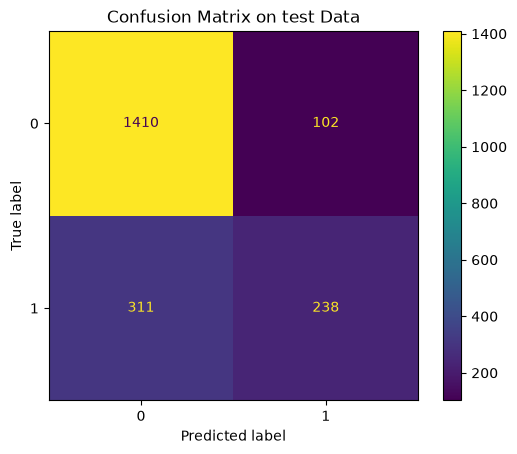

In [ ]:
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix using ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion Matrix on test Data')
plt.show()

# Regression

In [ ]:
claim_value = data_df[data_df['new_claim_value']>0]

x_reg = claim_value.copy()
y_reg = claim_value['new_claim_value']
x_reg.drop(columns=['new_claim_value','is_claim','claim_value_cat'],inplace=True)
x_reg_train, x_reg_test, y_reg_train, y_reg_test = train_test_split(x_reg, y_reg, test_size=0.2, random_state=42)

C:\Users\viraa\AppData\Local\Temp\ipykernel_21388\361585276.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  x_reg.drop(columns=['new_claim_value','is_claim','claim_value_cat'],inplace=True)


In [ ]:
x_reg_train_prepared = preprocess_pipeline.fit_transform(x_reg_train)

In [ ]:
regs = [
    ('Linear Regression', LinearRegression()),
    ('Decision Tree Regression ', DecisionTreeRegressor(random_state=42)),
    ('Random Forest', RandomForestRegressor(random_state=42)),
    ('SGD Regressor', SGDRegressor(random_state=42)),
    ('KNN Model ', KNeighborsRegressor()),
    ('Gradient Boosting', GradientBoostingRegressor(random_state=42)),
    ('XGBRegressor', XGBRegressor(random_state=42))
]

In [ ]:
# Create KFold object with 10 folds
reg_kf = KFold(n_splits=10, shuffle=True, random_state=42)

# Dictionary to store results
reg_results = {}

# Evaluate each classifier using cross-validation
for reg_name, reg in regs:
    cv_rmses = -cross_val_score(reg, x_reg_train_prepared, y_reg_train, cv=reg_kf, scoring='neg_root_mean_squared_error')
    reg_results[reg_name] = cv_rmses

reg_cv_scores_df = pd.DataFrame(reg_results)

c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\viraa\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\sklear

Text(0.5, 1.0, 'Cross-Validation Scores for Different Regressors')

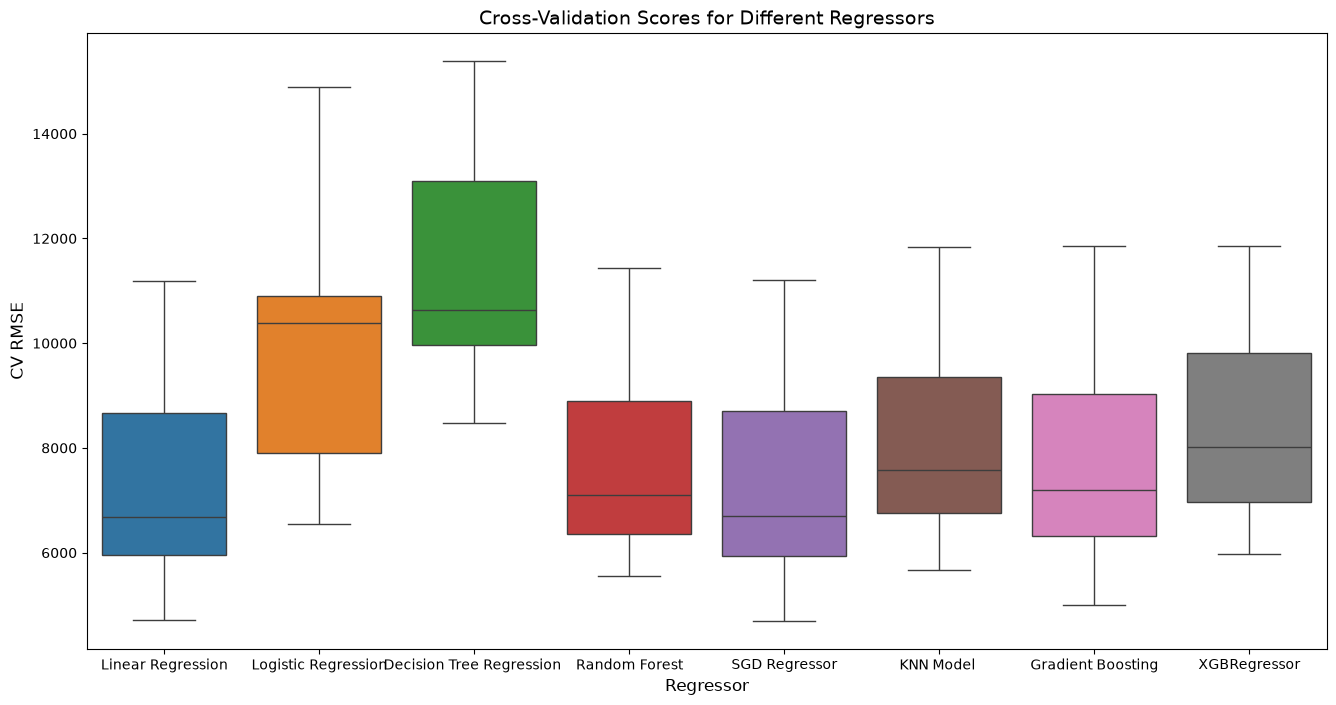

In [ ]:
# Plot scores
fig, ax = plt.subplots(figsize=(16, 8))
sns.boxplot(reg_cv_scores_df)

# Add axis labels
ax.set_xlabel('Regressor', fontsize=12)
ax.set_ylabel('CV RMSE', fontsize=12)
ax.set_title('Cross-Validation Scores for Different Regressors', fontsize=14)

In [ ]:
# Define the parameter grid for SGDRegressor
reg_param_grid = {
    'penalty': ['l2', 'l1', 'elasticnet'],
    'alpha': uniform(0.0001, 0.01),
    'learning_rate': ['constant', 'invscaling'],
    'eta0': uniform(0.001, 0.1),
    'max_iter': randint(100, 1000),
    'tol': uniform(1e-6, 1e-3)
}

# Initialise the regressor
sgd_regressor = SGDRegressor(random_state=42)

# Create random search
reg_random_search = RandomizedSearchCV(
    estimator=sgd_regressor,
    param_distributions=reg_param_grid,
    n_iter=500,
    scoring='neg_mean_squared_error',
    cv=reg_kf,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [ ]:
# Fit the SGDRegressor using RandomizedSearchCV
reg_random_search.fit(x_reg_train_prepared, y_reg_train)

score = np.sqrt(-reg_random_search.best_score_)

print("Best parameters found:", reg_random_search.best_params_)
print("Best cross-validation RMSE:", score)

Fitting 10 folds for each of 500 candidates, totalling 5000 fits
Best parameters found: {'alpha': np.float64(0.008548753109694546), 'eta0': np.float64(0.003327193573582587), 'learning_rate': 'invscaling', 'max_iter': 214, 'penalty': 'l2', 'tol': np.float64(0.0004970374542934063)}
Best cross-validation RMSE: 7605.881582243465


In [ ]:
# Define the parameter grid for SGDRegressor
reg_param_grid_gs = {
    'penalty': ['l2', 'l1', 'elasticnet'],
    'alpha': [0.004, 0.008, 0.012],
    'learning_rate': ['invscaling'],
    'eta0': [0.001, 0.003, 0.005],
    'max_iter': [180, 200, 220],
    'tol': [1e-5, 1e-4, 1e-6]
}

# Initialise the regressor
sgd_regressor = SGDRegressor(random_state=42)

# Create random search
reg_grid_search = GridSearchCV(
    estimator=sgd_regressor,
    param_grid=reg_param_grid_gs,
    scoring='neg_mean_squared_error',
    cv=reg_kf,
    verbose=1,
    n_jobs=-1
)

In [ ]:
# Fit the model
reg_grid_search.fit(x_reg_train_prepared, y_reg_train)

reg_score = np.sqrt(-reg_grid_search.best_score_)

# Print the best parameters and the best score
print("Best parameters found: ", reg_grid_search.best_params_)
print("Best cross-validation score: ", reg_score)

Fitting 10 folds for each of 243 candidates, totalling 2430 fits
Best parameters found:  {'alpha': 0.012, 'eta0': 0.003, 'learning_rate': 'invscaling', 'max_iter': 180, 'penalty': 'l2', 'tol': 1e-05}
Best cross-validation score:  7605.914272818823


In [ ]:
x_reg_test_prepared = preprocess_pipeline.fit_transform(x_reg_test)

y_reg_pred = reg_grid_search.best_estimator_.predict(x_reg_test_prepared)

mse = mean_squared_error(y_reg_test, y_reg_pred)
rmse = np.sqrt(mse)

mae = mean_absolute_error(y_reg_test, y_reg_pred)

print(f'RMSE: {rmse}')
print(f'MAE: {mae}')

RMSE: 8378.846093356431
MAE: 3556.2627508324217


In [ ]:
reg_grid_search.fit(
    x_reg_train_prepared,
    y_reg_train
)

best_sgd_model = reg_grid_search.best_estimator_

print("Best parameters:", reg_grid_search.best_params_)
print("Best CV RMSE:", np.sqrt(-reg_grid_search.best_score_))


Fitting 10 folds for each of 243 candidates, totalling 2430 fits
Best parameters: {'alpha': 0.012, 'eta0': 0.003, 'learning_rate': 'invscaling', 'max_iter': 180, 'penalty': 'l2', 'tol': 1e-05}
Best CV RMSE: 7605.914272818823


In [ ]:
# Preprocess test data using the fitted pipeline
x_reg_test_prepared = preprocess_pipeline.fit_transform(x_reg_test)

# Predict
sgd_pred = best_sgd_model.predict(x_reg_test_prepared)

# Evaluate
print("RMSE:", np.sqrt(mean_squared_error(y_reg_test, sgd_pred)))
print("MAE:", mean_absolute_error(y_reg_test, sgd_pred))
print("R2:", r2_score(y_reg_test, sgd_pred))

RMSE: 8378.846093356431
MAE: 3556.2627508324217
R2: -0.022756429773596487


# This project, I developed an end-to-end machine learning workflow to analyse car insurance claims using customer, demographic, driving-history and vehicle-related information.

The project was divided into two predictive tasks:

1. Classification – Claim Occurrence

The first task focused on predicting whether a policyholder would make an insurance claim. I explored multiple classification algorithms, including Logistic Regression, K-Nearest Neighbors, Decision Trees, Random Forest, Support Vector Machines, XGBoost, AdaBoost, Gradient Boosting, Bagging and CatBoost.

After comparing model performance using cross-validation, I selected XGBoost for further hyperparameter optimisation.

2. Regression – Claim Severity

The second task focused on estimating the claim amount for policyholders with a positive claim value. I evaluated multiple regression algorithms, including Linear Regression, SGDRegressor, Decision Tree, Random Forest, KNN, SVR and XGBoost.

Linear Regression and SGDRegressor performed competitively during initial cross-validation. I selected SGDRegressor for further hyperparameter optimisation.

The final regression evaluation produced an RMSE of approximately 8,379 and an MAE of approximately 3,556, with a negative R² score. This indicates that the model did not generalise sufficiently well to unseen claim amounts.

I also investigated the highly right-skewed distribution of claim amounts and experimented with a logarithmic target transformation and Random Forest Regression. These experiments highlighted the difficulty of predicting unusually large claims.

Overall, this project provided practical experience with data preprocessing, exploratory data analysis, feature engineering, classification, regression, cross-validation, hyperparameter optimisation and model evaluation.

12. Limitations and Future Improvements

Despite implementing several machine learning techniques, the project has limitations:

Target imbalance and distribution: Claim occurrence and claim amounts may have uneven distributions, affecting model performance.

Skewed claim amounts: The regression target exhibited substantial positive skewness, making large claim amounts difficult to predict.

Limited predictive information: The available customer and vehicle features may not capture all factors influencing insurance claims.

Model generalisation: The regression model's negative test R² indicates that its predictive performance requires further improvement.

Feature engineering: Additional interaction features, domain-specific variables and transformations could improve predictive power.

Model interpretation: Further work using permutation importance or SHAP could provide better insight into the factors influencing predictions.

Future Work

Potential improvements include:

Experimenting with target transformations and robust regression techniques.

Investigating Gradient Boosting, XGBoost and CatBoost for claim severity prediction.

Exploring class imbalance handling and classification threshold optimisation.

Performing more rigorous cross-validation with preprocessing fitted separately within each fold.

Applying SHAP or permutation importance for model interpretability.

Developing a combined two-stage model to estimate expected claim cost using claim probability and predicted claim severity.

The project establishes a foundation for further work in insurance risk modelling and predictive analytics.